# Deep-Sea Classification: Context Reliance & Depth Degradation
This notebook imports from the project's `.py` modules and runs the full pipeline on Colab's GPU.

In [ ]:
# --- Environment bootstrap (Colab or local; no Google Drive) ---
import os, sys
try:
    import google.colab          # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    # Pull the code from the PUBLIC repo — no Drive. (The large FathomNet metadata is downloaded
    # later in section 1, not stored in git.)
    if not os.path.isdir("cv-project"):
        !git clone --depth 1 https://github.com/kay-asp/cv-project.git
    %cd cv-project
    # Colab already ships torch/numpy/pandas/scipy/matplotlib; add only the extras.
    %pip install -q fathomnet grad-cam pycocotools
# Local: install from requirements.txt (see README) and launch Jupyter from the repo root.

sys.path.insert(0, os.getcwd())
print("Working directory:", os.getcwd())

# Training Pipeline
Trains both models (shallow-only and all-depths control), runs predictions,
computes Grad-CAM attribution and CRS, runs background interventions, and
saves all results to CSV. Run this notebook once on a Colab GPU.

## 0 · Setup: environment & dependencies
The bootstrap cell above works both on Colab (clones this public repo, installs the extras) and locally (uses the repo you launched Jupyter from). No Google Drive is required.

In [4]:
# Verify GPU is available
import torch
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')

import logging, importlib
logging.getLogger("urllib3.connectionpool").setLevel(logging.ERROR)

Using device: cuda


In [ ]:
# Import project modules (from the repo root)
import config
import data
import model
import attribution
import evaluation
import analysis
import extensions

# Set seed for reproducibility early in notebook execution
model.set_seed(config.RANDOM_SEED)

## 1 · Data loading & preprocessing

In [ ]:
# FathomNet COCO metadata (train.json). It's ~280 MB — too large to commit — so fetch it once
# into data/ and reuse it on later runs. train.json is the only metadata file this pipeline needs;
# data/depth_cache.csv is built from the FathomNet API on the first run (see data.load_fathomnet_metadata).
import os, urllib.request

os.makedirs(config.DATA_DIR, exist_ok=True)
if not os.path.exists(config.TRAIN_PATH):
    url = "https://database.fathomnet.org/static/segmentations/train.json"
    print(f"Downloading {url}\n  -> {config.TRAIN_PATH}  (~280 MB, one time)...")
    urllib.request.urlretrieve(url, config.TRAIN_PATH)
print(f"train.json ready: {os.path.getsize(config.TRAIN_PATH) / 1e6:.0f} MB")

loading annotations into memory...
Done (t=14.54s)
creating index...
index created!
Loaded depth cache: 119096 entries
Need to fetch depth for 0 / 119096 images
Total images: 280118
Depth range: 0m – 5955m


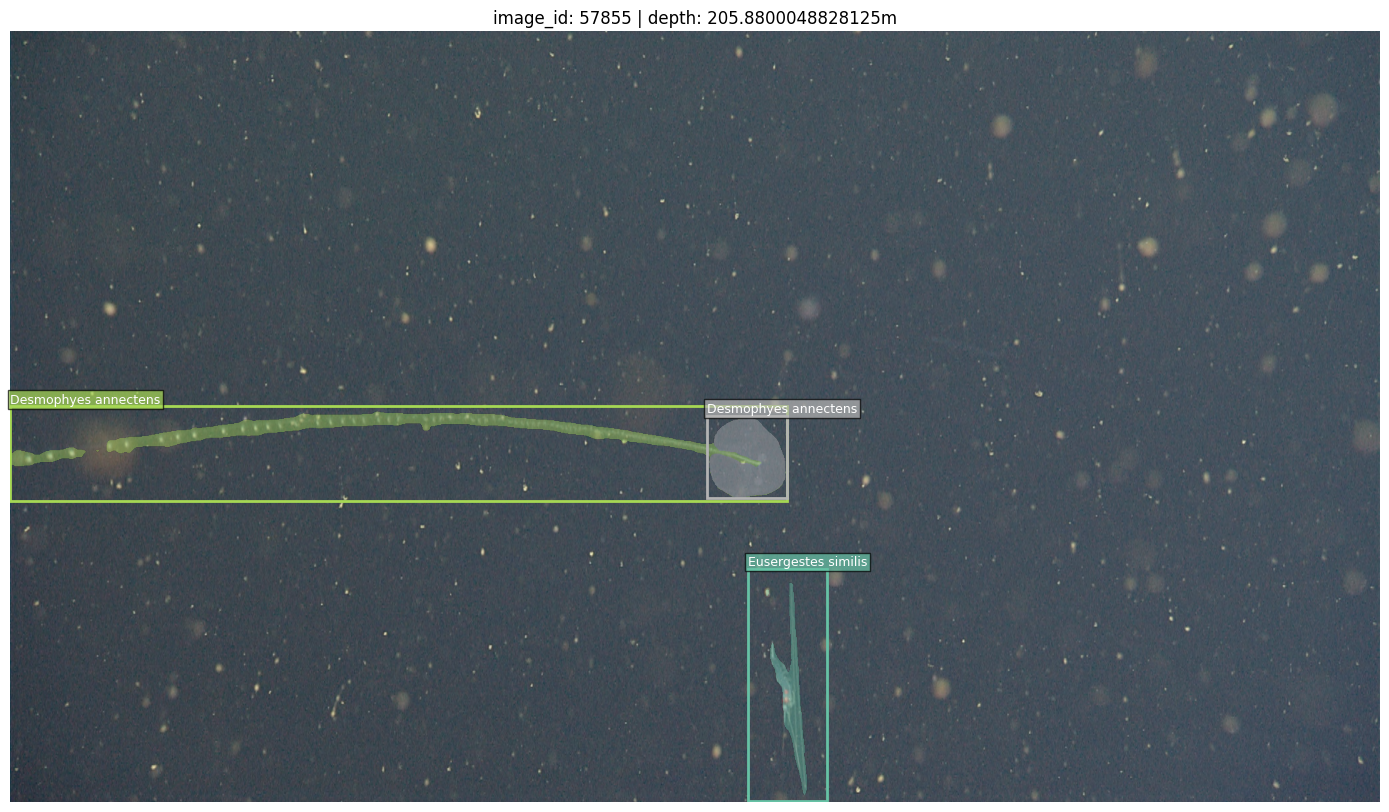

In [7]:
# Load FathomNet metadata
df, coco = data.load_fathomnet_metadata(config.TRAIN_PATH, config.DEPTH_PATH)
#df_test, coco_test = data.load_fathomnet_metadata(config.TEST_PATH, config.DEPTH_PATH)

# Merged train and test so depth splits can be created later
# df: image_id, ann_id, species, bbox, depth_m, width, height
# coco: pycocotools COCO object (for mask retrieval later)
# df, coco = data.load_merged_metadata(df_train, df_test, coco_train, coco_test)

# Test
print(f'Total images: {len(df)}')
print(f'Depth range: {df["depth_m"].min():.0f}m – {df["depth_m"].max():.0f}m')

try:
    data.show_sample(coco, df, idx=65909)
except Exception as e:
    print(f"Warning: Failed to show sample image due to server error (skipping): {e}")

In [10]:
import pandas as pd
data.summarise_depth_distribution(df)

def threshold_sweep(df, thresholds, min_n=5):
    rows = []
    for t in thresholds:
        counts = df.dropna(subset=['depth_m']).groupby('species')['depth_m'].apply(
            lambda d: pd.Series({
                'n_shallow': (d <= t).sum(),
                'n_deep': (d > t).sum(),
            })
        ).unstack()
        n_qualifying = ((counts['n_shallow'] >= min_n) & (counts['n_deep'] >= min_n)).sum()
        rows.append({'threshold': t, 'n_qualifying_species': n_qualifying})
    return pd.DataFrame(rows)

thresholds = [269, 427, 597, 837, 896, 1056, 1236, 1657, 3040]
display(threshold_sweep(df, thresholds, min_n=5))  # species counts for Table I

counts_1056 = df.dropna(subset=['depth_m']).groupby('species')['depth_m'].apply(
    lambda d: pd.Series({'n_shallow': (d <= 1055.9).sum(), 'n_deep': (d > 1055.9).sum()})
).unstack()
qualifying_1056 = counts_1056[(counts_1056['n_shallow'] >= 5) & (counts_1056['n_deep'] >= 5)]
qualifying_1056['n_deep'].describe()



count    208286.000000
mean       1189.382294
std         962.826550
min           0.000000
25%         539.706482
50%         895.799988
75%        1309.929962
max        5954.757000
Name: depth_m, dtype: float64

 percentile  depth_m  n_shallow  n_deep
         10    269.0      20835  187451
         20    427.0      41658  166628
         30    597.5      62516  145770
         40    837.5      83337  124949
         50    895.8     104146  104140
         60   1055.9     124975   83311
         70   1236.0     145803   62483
         80   1657.1     166629   41657
         90   3040.1     187461   20825


,threshold,n_qualifying_species
0,269,132
1,427,215
2,597,242
3,837,307
4,896,322
5,1056,314
6,1236,303
7,1657,264
8,3040,137


,n_deep
count,314.000000
mean,214.238854
std,636.971175
min,5.000000
25%,12.000000
50%,37.500000
75%,130.750000
max,7927.000000


In [9]:
# Split into shallow / deep
threshold = config.DEPTH_SHALLOW_MAX
shallow_df, deep_df = data.split_shallow_deep(df, threshold)

# Keep species with enough annotations on BOTH sides of the split
shallow_df, deep_df = data.restrict_to_common_species(shallow_df, deep_df, min_n=5)
all_df = pd.concat([shallow_df, deep_df], ignore_index=True)
species_list = sorted(shallow_df['species'].unique())
print(f'Shallow: {len(shallow_df)} | Deep: {len(deep_df)} | Species: {len(species_list)}')

Dropping 71832 rows with missing depth_m (25.6% of data)
Threshold 1056m -> shallow: 124982 (60.0%), deep: 83304 (40.0%)
Species with >= 5 annotations in BOTH splits: 314
Kept -> shallow: 105862 annotations | deep: 67250 annotations
Shallow: 105862 | Deep: 67250 | Species: 314


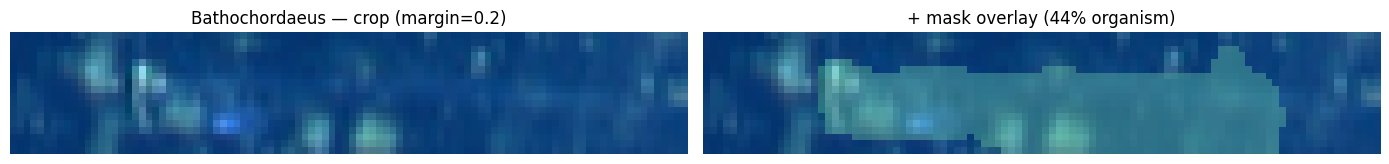

idx=20 skipped: Could not download image 183145


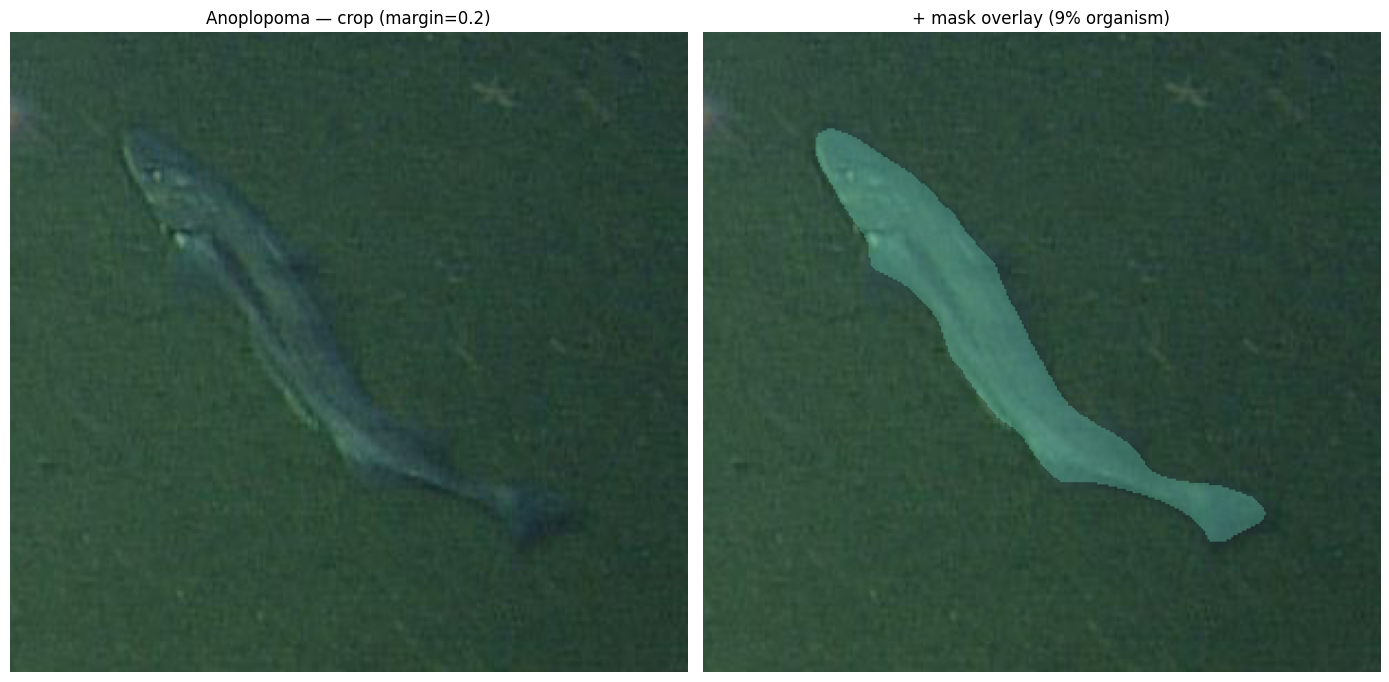

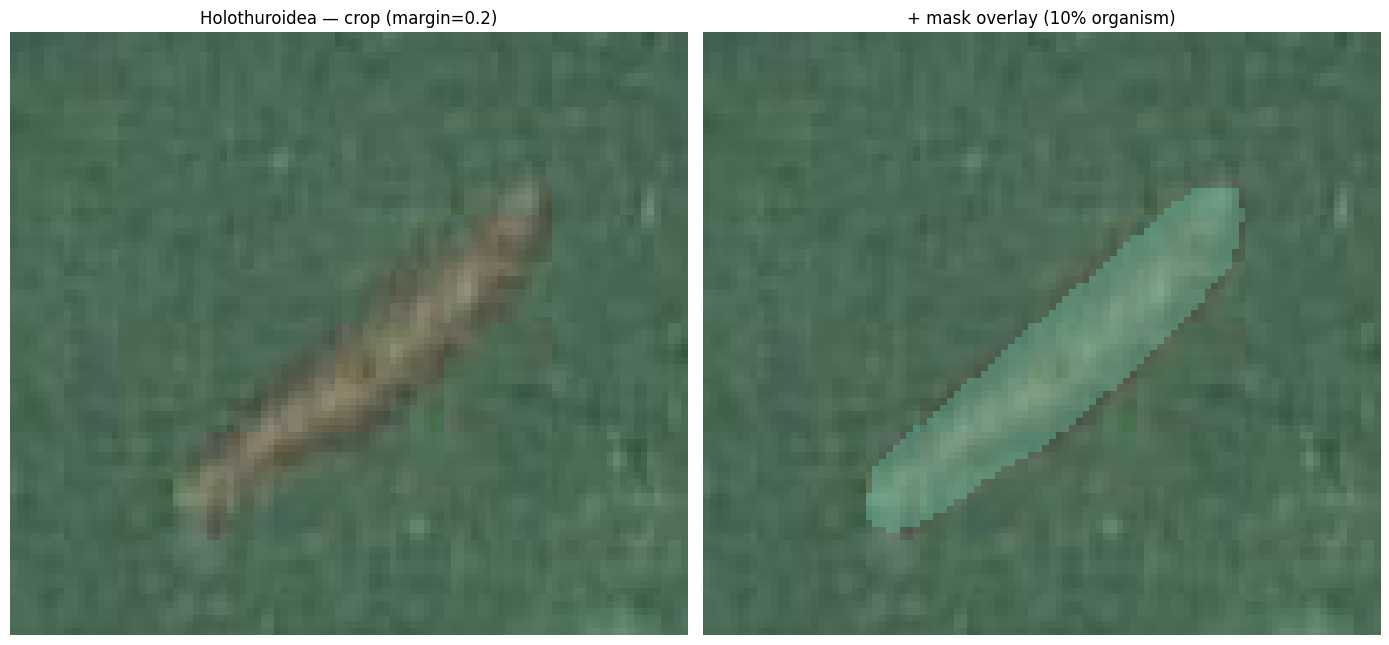

In [10]:
# Crop a few annotations and check that crop_to_bounding_box keeps image and mask aligned
# check a handful, ideally different species and image sizes
for i in [0, 20, 25, 30]:
    row = df.iloc[i]
    try:
        img = data.get_image(coco, row['image_id'])
        full_mask = coco.annToMask(coco.loadAnns([int(row['ann_id'])])[0])
        crop, crop_mask, _ = data.crop_to_bounding_box(img, row['bbox'], mask=full_mask)
    except (RuntimeError, ValueError) as e:   # download failed / degenerate bbox
        print(f"idx={i} skipped: {e}")
        continue
    data.display_image(crop, masks=crop_mask, show_original=True,
                       title=f"{row['species']} — crop (margin={config.CROP_MARGIN})")

In [11]:
# Crops: restore from the shared archive, or download once and create it
if os.path.exists(config.CROP_ARCHIVE):
    if not os.path.isdir(config.CROP_DIR):
        data.restore_dir(config.CROP_ARCHIVE, config.CROP_DIR)
n_saved, _ = data.prepare_crops(all_df)
if n_saved or not os.path.exists(config.CROP_ARCHIVE):
    data.archive_dir(config.CROP_DIR, config.CROP_ARCHIVE)   # only rewrite the shared archive when there are new crops

# Crops that could not be downloaded are dropped so the loaders all agree
shallow_df = data.drop_missing_crops(shallow_df)
deep_df = data.drop_missing_crops(deep_df)
all_df = pd.concat([shallow_df, deep_df], ignore_index=True)

# Build DataLoaders
train_loader = data.get_dataloaders(shallow_df, split='train', species_list=species_list)
val_loader   = data.get_dataloaders(shallow_df, split='val', species_list=species_list)
shallow_test_loader = data.get_dataloaders(shallow_df, split='test', species_list=species_list)
deep_test_loader    = data.get_dataloaders(deep_df, split='test', species_list=species_list)



Restored 173080 files to /content/crops/
32 crops missing across 24 images to fetch
Done: saved 0 crops, 32 failed/skipped
Dropping 17 rows with no crop on disk
Dropping 15 rows with no crop on disk
train: 73711 crops, 314 classes
val: 10811 crops, 314 classes
test: 21323 crops, 314 classes
test: 12926 crops, 314 classes


## 2 · Control (trained on all depths)
Builds control classifier trained on all depths.
Holds architecture and training procedure fixed and varies only the training distribution,
so degradation differences can be attributed to distribution shift rather than model capacity.

In [12]:
import time
import numpy as np
import pandas as pd
import os

SKIP_CONTROL = False  # True = classifier only
HISTORY_RUN = "run2"  # label for the val-accuracy histories saved below; change it for each fresh training run
                      # (comparing-the-runs.ipynb compares them to check the seeded training reproduces)

control_results = None
if not SKIP_CONTROL:
    print("\n--- Training control model (all depths) ---")
    control_ckpt_path = config.MODEL_SAVE_PATH + "control_resnet50.pt"

    # Seed before creating the control model
    model.set_seed(config.RANDOM_SEED)

    control = model.build_classifier(num_classes=len(species_list), pretrained=config.PRETRAINED)

    all_loader = data.get_dataloaders(all_df, split="train", species_list=species_list)
    all_val_loader = data.get_dataloaders(all_df, split="val", species_list=species_list)

    if os.path.exists(control_ckpt_path):
        print(f"Found existing checkpoint at {control_ckpt_path} - loading instead of retraining")
        control = model.load_checkpoint(control, control_ckpt_path)
        # Note: If loading from a saved checkpoint, control_history won't be defined here.
        # Let's initialize a placeholder or define it to avoid NameError on reload
        control_history = {"val_acc": []}
        control_trained = False   # loaded weights -> cached eval below is still valid
    else:
        t0 = time.time()
        control, control_history = model.train(control, all_loader, all_val_loader,
                                               epochs=config.EPOCHS, lr=config.LEARNING_RATE,
                                               resume_path=control_ckpt_path + ".resume")
        model.save_checkpoint(control, control_ckpt_path)
        print(f"Control training took {(time.time() - t0) / 60:.1f} min, saved to {control_ckpt_path}")
        # Only after real training: a loaded checkpoint has no history, and saving its empty
        # placeholder would overwrite the record of the run that produced it
        np.save(os.path.join(config.MODEL_SAVE_PATH, f"control_history_{HISTORY_RUN}.npy"),
                np.array(control_history["val_acc"]))
        control_trained = True    # fresh weights -> any cached eval is stale, recompute below

    # Evaluating the control model is two full GPU passes (shallow + deep test). Cache the
    # predictions and reuse them on reruns, recomputing only when the control was just retrained.
    # Delete results/control_eval_predictions.csv by hand to force a recompute.
    control_eval_path = os.path.join(config.RESULTS_DIR, "control_eval_predictions.csv")
    if os.path.exists(control_eval_path) and not control_trained:
        print(f"Reusing cached control predictions from {control_eval_path}")
        cp = pd.read_csv(control_eval_path)
        c_shallow_preds = cp[cp["split"] == "shallow"].drop(columns="split")
        c_deep_preds    = cp[cp["split"] == "deep"].drop(columns="split")
        c_shallow_acc = evaluation.accuracy_from_predictions(c_shallow_preds, species_list)
        c_deep_acc    = evaluation.accuracy_from_predictions(c_deep_preds, species_list)
        control_results = {
            "shallow_acc": c_shallow_acc,
            "deep_acc": c_deep_acc,
            "degradation": evaluation.compute_degradation(c_shallow_acc, c_deep_acc),
            "shallow_preds": c_shallow_preds,
            "deep_preds": c_deep_preds,
        }
    else:
        control_results = evaluation.evaluate_control_model(
            control, shallow_test_loader, deep_test_loader, species_list
        )
        os.makedirs(config.RESULTS_DIR, exist_ok=True)
        pd.concat([control_results["shallow_preds"].assign(split="shallow"),
                   control_results["deep_preds"].assign(split="deep")]).to_csv(control_eval_path, index=False)

    print(f"Control mean shallow accuracy: {pd.Series(control_results['shallow_acc']).mean():.3f}")
    print(f"Control mean deep accuracy:    {pd.Series(control_results['deep_acc']).mean():.3f}")


--- Training control model (all depths) ---
Random seed set to 42
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 163MB/s]


train: 121132 crops, 314 classes
val: 17699 crops, 314 classes
Found existing checkpoint at checkpoints/control_resnet50.pt - loading instead of retraining
Reusing cached control predictions from results/control_eval_predictions.csv
Control mean shallow accuracy: 0.528
Control mean deep accuracy:    0.539


## 3 · Train classifier (shallow-depth only)

In [13]:
print("\n--- Training classifier (shallow only) ---")

# Seed before creating the shallow classifier
model.set_seed(config.RANDOM_SEED)

classifier = model.build_classifier(num_classes=len(species_list))

ckpt_path = config.MODEL_SAVE_PATH + "shallow_resnet50.pt"
if os.path.exists(ckpt_path):
    print(f"Found existing checkpoint at {ckpt_path} - loading instead of retraining")
    classifier = model.load_checkpoint(classifier, ckpt_path)
    # Initialize placeholder to avoid NameError on reload
    shallow_history = {"val_acc": []}
    shallow_trained = False   # loaded weights -> cached predictions/CRS below are still valid
else:
    t0 = time.time()
    classifier, shallow_history = model.train(classifier, train_loader, val_loader,
                                      epochs=config.EPOCHS, lr=config.LEARNING_RATE,
                                      resume_path=ckpt_path + ".resume")
    model.save_checkpoint(classifier, ckpt_path)
    print(f"Training took {(time.time() - t0) / 60:.1f} min, saved to {ckpt_path}")
    # Only after real training (see the control cell); HISTORY_RUN is set there
    np.save(os.path.join(config.MODEL_SAVE_PATH, f"shallow_history_{HISTORY_RUN}.npy"),
            np.array(shallow_history["val_acc"]))
    shallow_trained = True    # fresh weights -> predictions/CRS caches are stale, recompute them


--- Training classifier (shallow only) ---
Random seed set to 42
Found existing checkpoint at checkpoints/shallow_resnet50.pt - loading instead of retraining


## 4 · Evaluation

In [14]:
import os
import pandas as pd

predictions_path = "results/predictions.csv"
REUSE_PREDICTIONS = True   # reuse results/predictions.csv; a freshly trained model auto-refreshes it

# Reuse the cached shallow-model predictions across reruns. A freshly trained classifier
# (shallow_trained, set in section 3) always recomputes, and a file missing the expected
# columns is ignored, so a stale or malformed cache can't slip through.
# Delete results/predictions.csv (or set REUSE_PREDICTIONS = False) to force a rebuild.
pred_cols = {"image_id", "ann_id", "species", "pred", "confidence", "correct"}
cached_preds = None
if REUSE_PREDICTIONS and not shallow_trained and os.path.exists(predictions_path):
    p = pd.read_csv(predictions_path)
    if {"model", "split"} <= set(p.columns) and pred_cols <= set(p.columns):
        cached_preds = p

if cached_preds is not None:
    print(f"Reusing cached predictions from {predictions_path}")
    main = cached_preds[cached_preds["model"] == "shallow"]
    shallow_preds = main[main["split"] == "shallow"].drop(columns=["model", "split"])
    deep_preds    = main[main["split"] == "deep"].drop(columns=["model", "split"])
else:
    shallow_preds = evaluation.predict(classifier, shallow_test_loader)
    deep_preds    = evaluation.predict(classifier, deep_test_loader)

shallow_acc = evaluation.accuracy_from_predictions(shallow_preds, species_list)
deep_acc    = evaluation.accuracy_from_predictions(deep_preds, species_list)
degradation = evaluation.compute_degradation(shallow_acc, deep_acc)

print(f"Shallow preds: {len(shallow_preds)} | Deep preds: {len(deep_preds)}")  # expect 21323 | 12926
print(f"Mean shallow accuracy: {pd.Series(shallow_acc).mean():.3f}")
print(f"Mean deep accuracy:    {pd.Series(deep_acc).mean():.3f}")
# Majority class is fixed from the training set and scored as mean per-species accuracy,
# so it sits on the same scale as the macro accuracies above (~1 / n_species_present)
majority_acc = evaluation.majority_class_baseline(train_loader, shallow_test_loader, species_list)
print(f"Majority-class baseline (mean per-species acc): {majority_acc:.3f}")

Reusing cached predictions from results/predictions.csv
Shallow preds: 21323 | Deep preds: 12926
Mean shallow accuracy: 0.513
Mean deep accuracy:    0.307
Majority-class baseline (mean per-species acc): 0.003


### Save results

In [15]:
# Per-species accuracy -> results/per_species_accuracy.csv
# Per-image predictions -> results/predictions.csv
per_species_df, predictions_df = evaluation.save_results(
    species_list, shallow_preds, deep_preds, control_results)
per_species_df.head()

Saved 314 species to results/per_species_accuracy.csv
Saved 68498 predictions to results/predictions.csv


,n_shallow_test,n_deep_test,shallow_acc,deep_acc,degradation,control_shallow_acc,control_deep_acc,control_degradation
species,,,,,,,,
Acanthascinae,70,10,0.500000,0.000000,0.500000,0.114286,0.100000,0.014286
Acanthephyra,0,10,NaN,0.500000,NaN,NaN,0.600000,NaN
Acanthogorgia,4,3,0.250000,0.333333,-0.083333,0.500000,0.666667,-0.166667
Acesta,11,1,1.000000,0.000000,1.000000,0.909091,0.000000,0.909091
Actiniaria,444,432,0.725225,0.648148,0.077077,0.743243,0.745370,-0.002127


## 5 · Attribution & Context Reliance Score

### Crop Masks

test: 21323 crops, 314 classes
Restored 68498 files to /content/masks/
Masks: 0 newly saved, 21323 already cached in /content/masks/


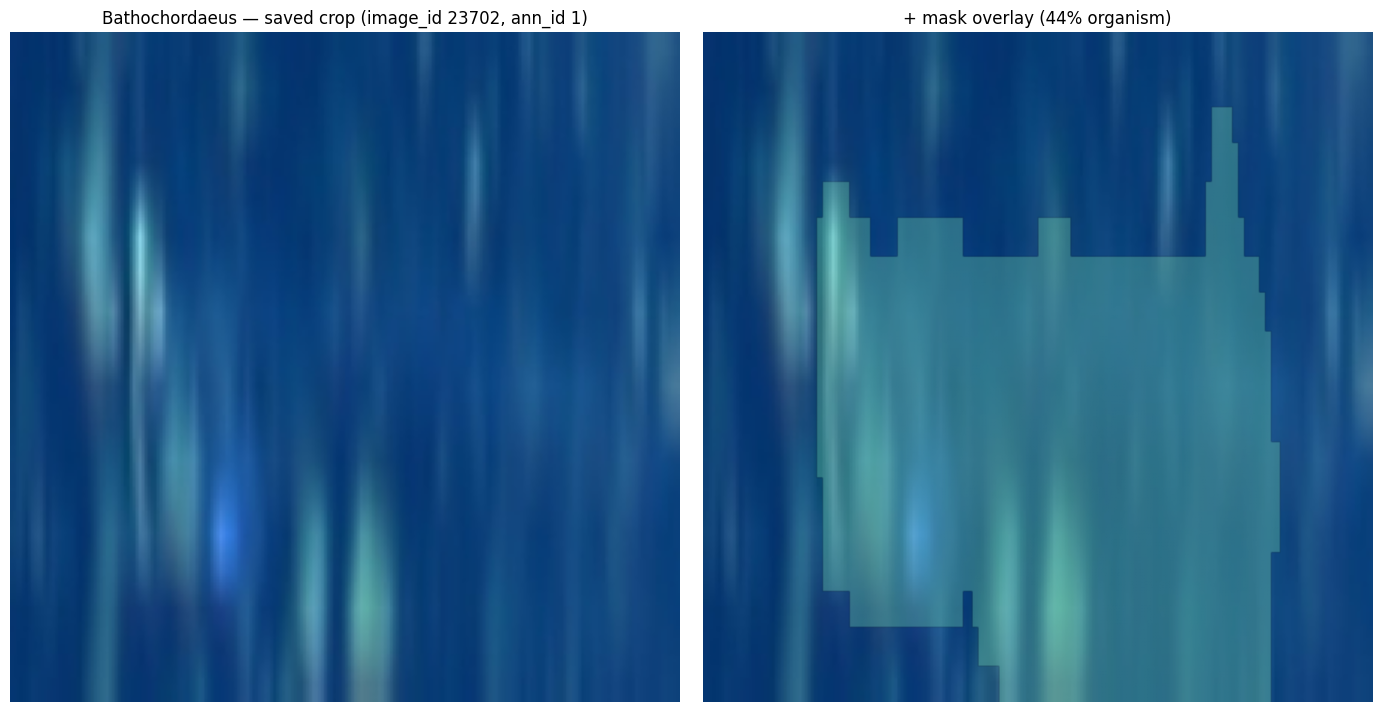

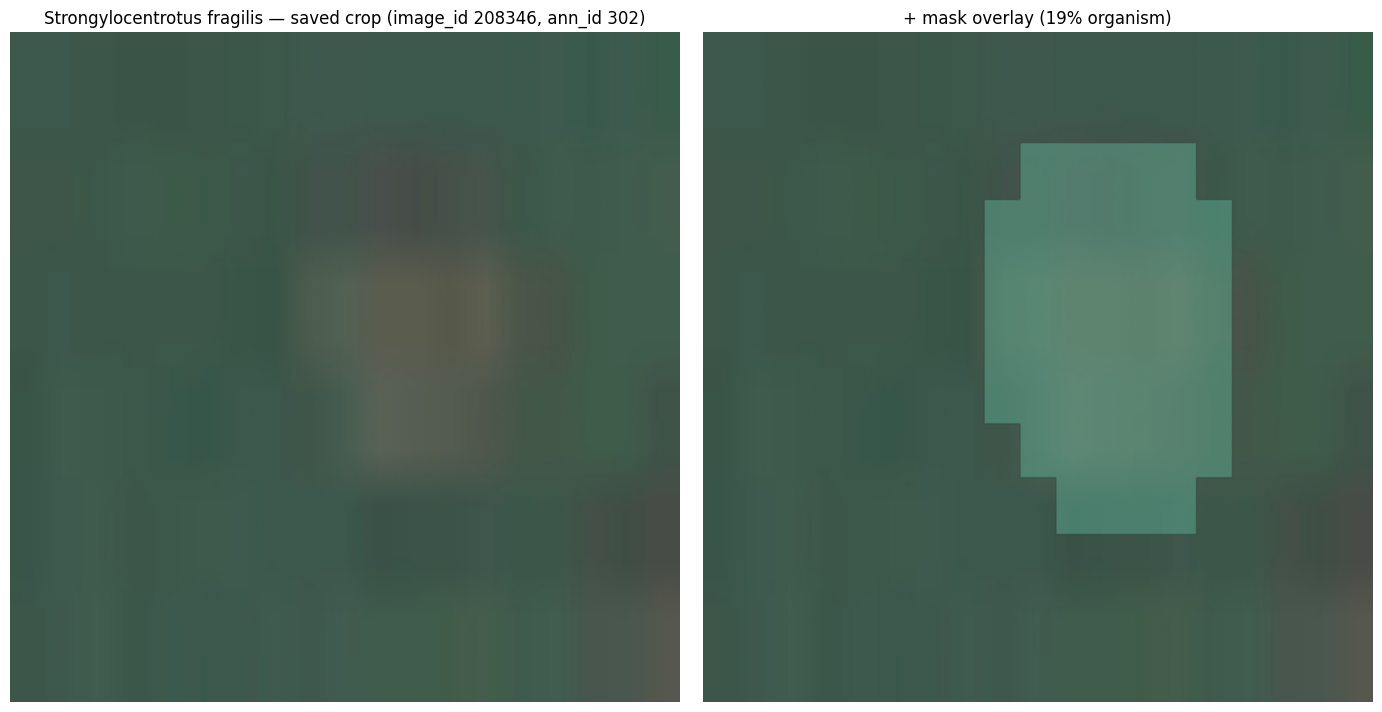

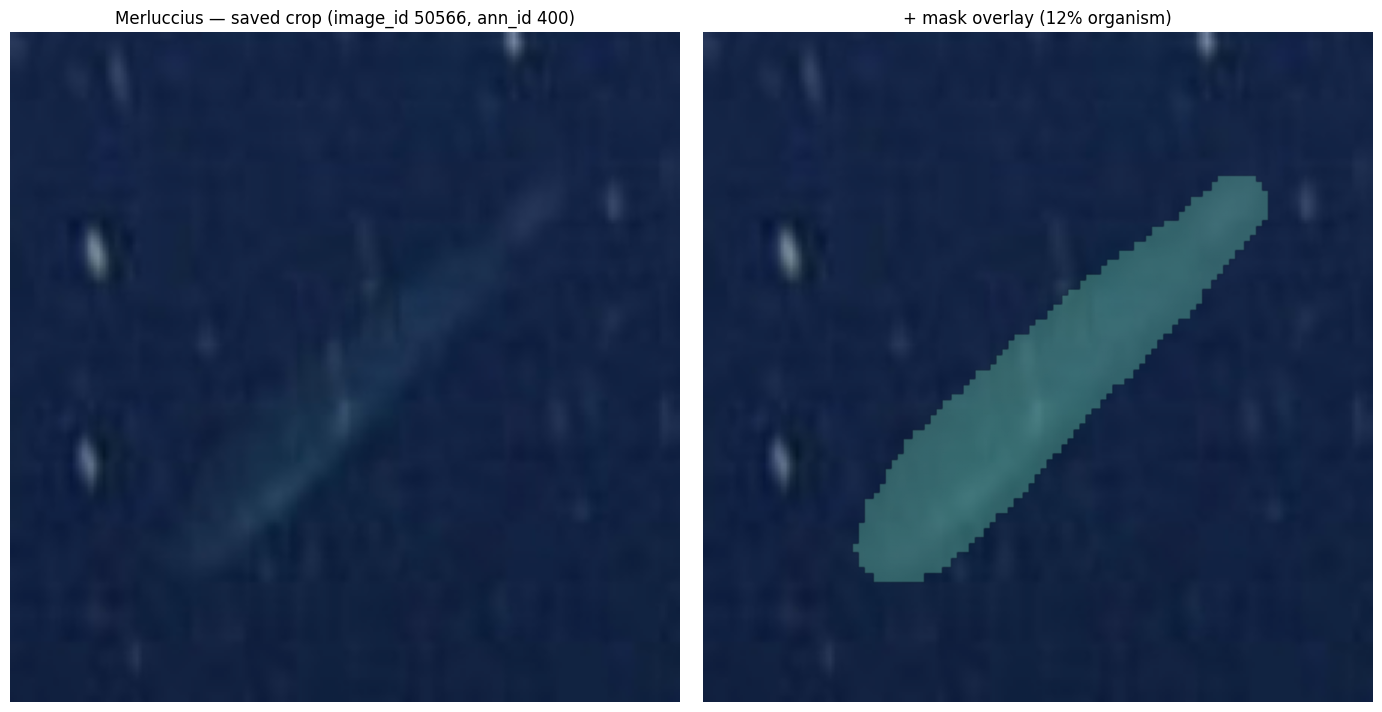

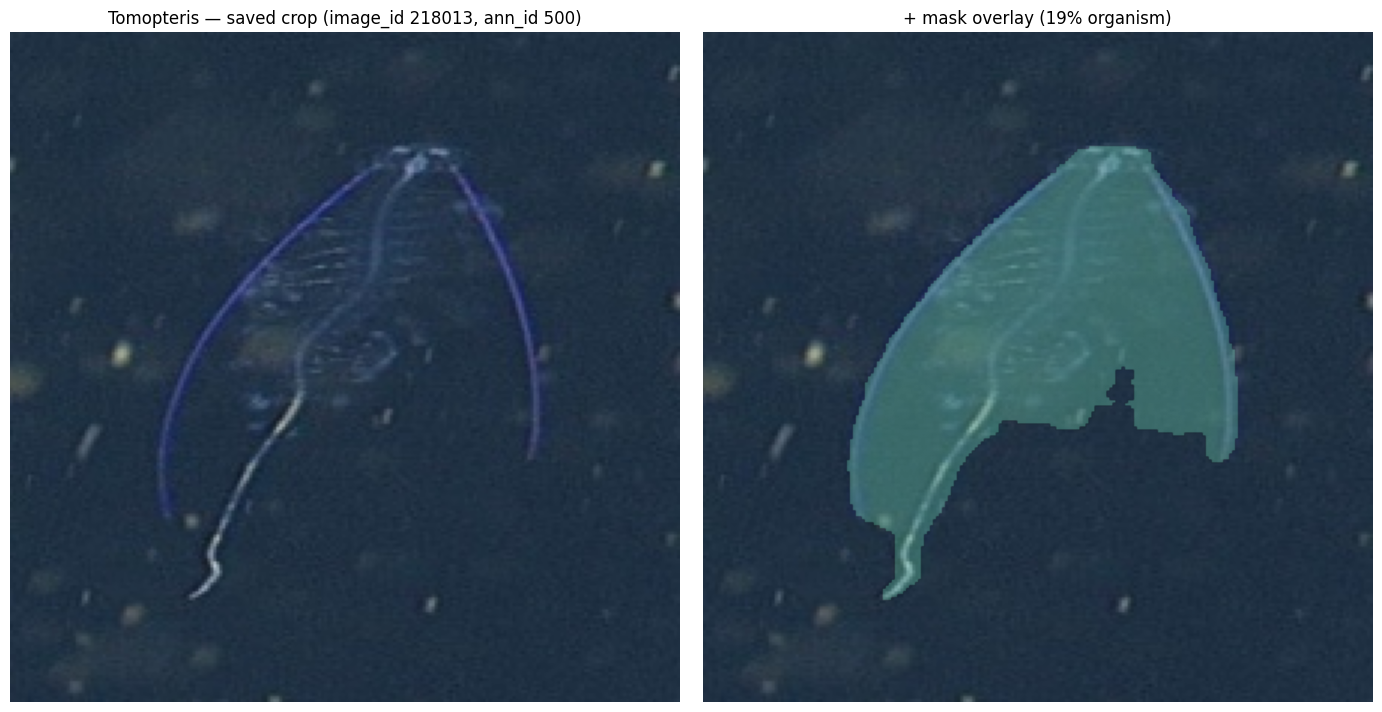

In [16]:
# Save crop masks

# Same crops as shallow_test_loader, plus crop-aligned masks (for CRS in section 5)
shallow_test_mask_loader = data.get_dataloaders(shallow_df, split='test', species_list=species_list,
                                               coco=coco)
# Masks: restore from the shared archive, compute any missing, re-archive only if new ones were made
if os.path.exists(config.MASK_ARCHIVE) and not os.path.isdir(config.MASK_DIR):
    data.restore_dir(config.MASK_ARCHIVE, config.MASK_DIR)
n_new_masks = data.prepare_masks(shallow_test_mask_loader)
if n_new_masks or not os.path.exists(config.MASK_ARCHIVE):
    data.archive_dir(config.MASK_DIR, config.MASK_ARCHIVE)

# show_saved_crops: loads the saved 224x224 crops + get_crop_mask masks - tests what Grad-CAM/CRS actually receive is aligned
data.show_saved_crops(shallow_test_mask_loader, idxs=[0, 20, 25, 30])

### Grad-CAM Heatmaps

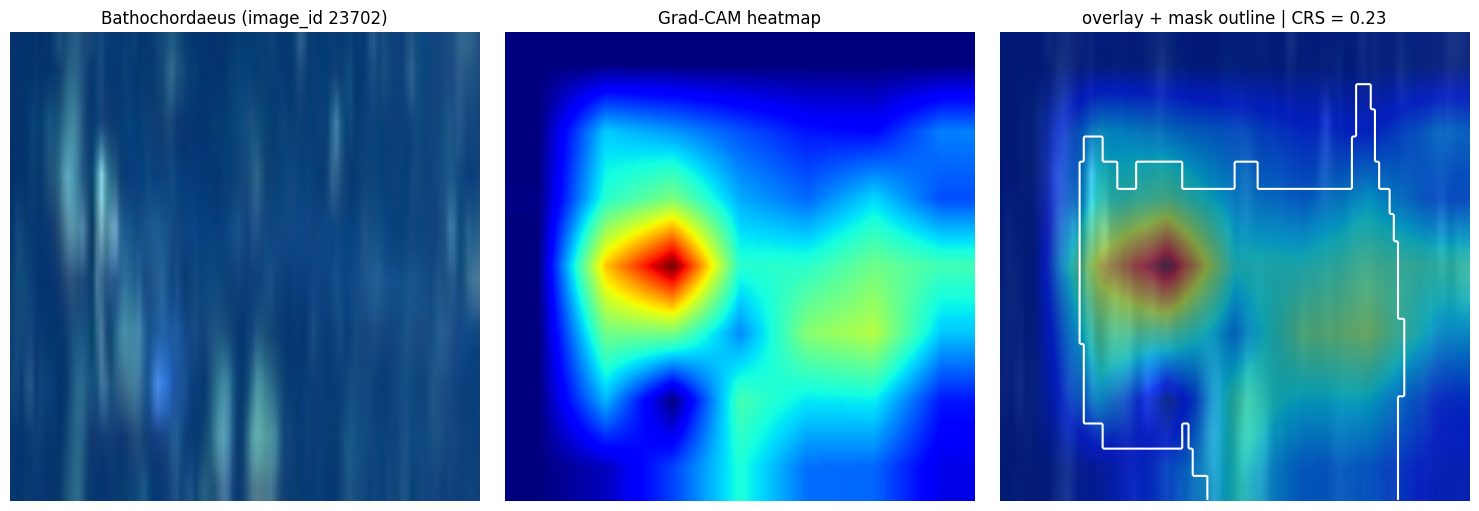

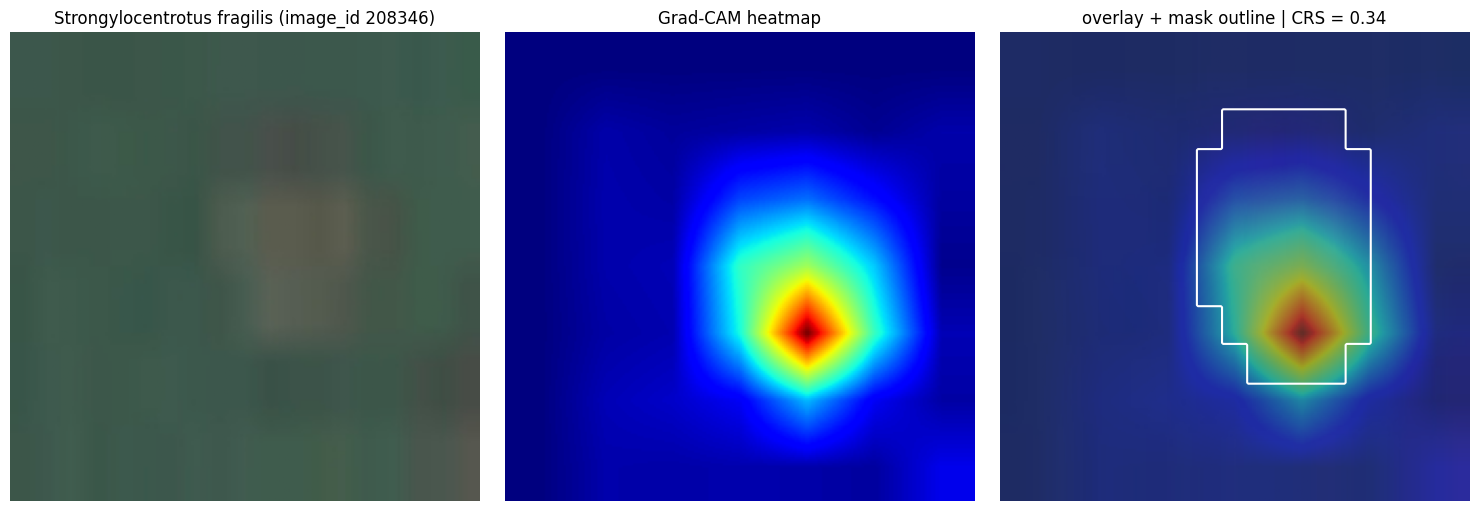

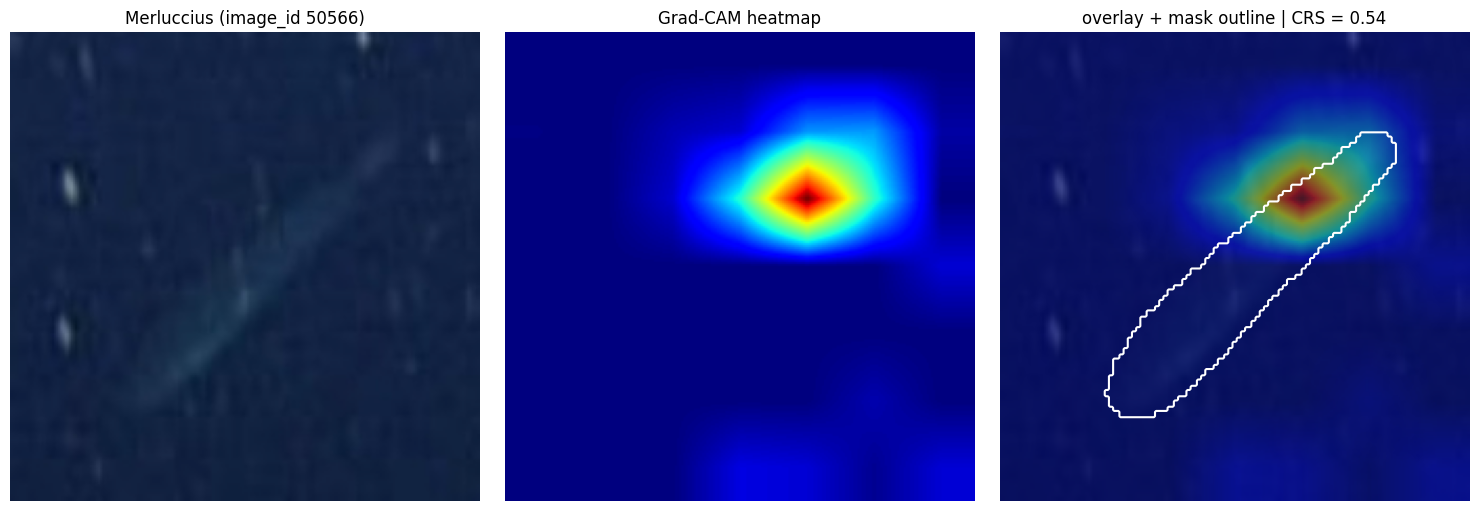

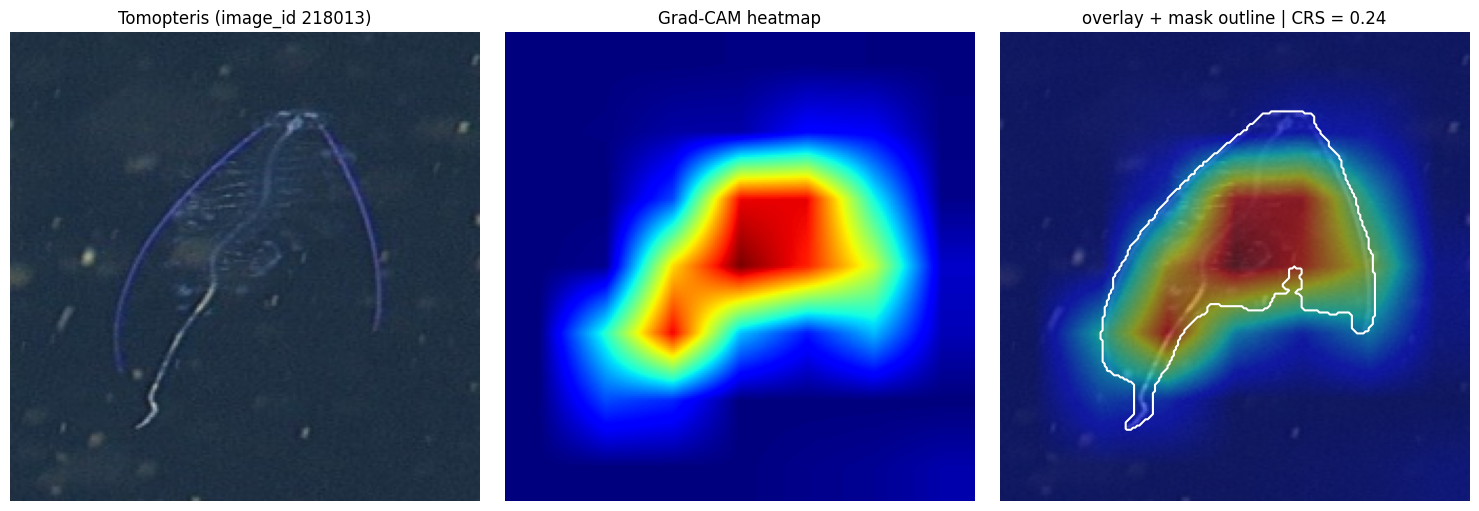

In [17]:
# Grad-CAM heatmaps on a few shallow test crops (explained for the true species)
# Mask outline in white (target organism, undilated); CRS = fraction of the heatmap outside the
# dilated organism mask, scored on the 7x7 Grad-CAM grid
import matplotlib.pyplot as plt

ds = shallow_test_mask_loader.dataset
mean = torch.tensor(data.IMAGENET_MEAN).view(3, 1, 1)
std = torch.tensor(data.IMAGENET_STD).view(3, 1, 1)

for i in [0, 20, 25, 30]:
    img, label, mask = ds[i]
    heatmap = attribution.compute_gradcam(classifier, img, label)   # normalised, for display
    crs = attribution.compute_crs(attribution.compute_gradcam(classifier, img, label, raw=True), mask)
    rgb = (img * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()  # undo Normalize

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    axes[0].imshow(rgb)
    axes[0].set_title(f"{species_list[label]} (image_id {ds.image_ids[i]})")
    axes[1].imshow(heatmap, cmap='jet', vmin=0, vmax=1)
    axes[1].set_title("Grad-CAM heatmap")
    axes[2].imshow(rgb)
    axes[2].imshow(heatmap, cmap='jet', alpha=0.5, vmin=0, vmax=1)
    axes[2].contour(mask.numpy(), levels=[0.5], colors='white', linewidths=1.5)
    axes[2].set_title(f"overlay + mask outline | CRS = {crs:.2f}")
    for ax in axes:
        ax.axis('off')
    plt.tight_layout()
    plt.show()

In [18]:
# Baseline attribution maps (also save to results.csv)
# Scored like Grad-CAM: same target-organism masks, dilated, on the 7x7 grid, and on the same
# correctly classified shallow test crops as the species CRS, so the comparison is like-for-like.
correct_ids = set(shallow_preds.loc[shallow_preds['correct'], 'ann_id'])
correct_mask_loader = data.get_dataloaders(shallow_df[shallow_df['ann_id'].isin(correct_ids)],
                                           split='test', species_list=species_list, coco=coco)
uniform_crs  = attribution.compute_species_baseline_crs(correct_mask_loader, species_list, 'uniform')
gaussian_crs = attribution.compute_species_baseline_crs(correct_mask_loader, species_list, 'gaussian')
per_species_df['uniform_crs']  = pd.Series(uniform_crs)
per_species_df['gaussian_crs'] = pd.Series(gaussian_crs)
results_path = os.path.join(config.RESULTS_DIR, 'results.csv')
per_species_df.to_csv(results_path)


test: 17677 crops, 314 classes
uniform baseline CRS: scored 17677 / 17677 images
gaussian baseline CRS: scored 17677 / 17677 images


### Context-Reliance Score

In [ ]:
# Per-image CRS on the shallow test set; species CRS is averaged from this same table
# Delete results/image_crs.csv to force a recompute.
img_crs_path = os.path.join(config.RESULTS_DIR, 'image_crs.csv')
_cached_ic = pd.read_csv(img_crs_path) if os.path.exists(img_crs_path) else None
if (_cached_ic is not None and not shallow_trained and 'crs_pred' in _cached_ic.columns
        and (_cached_ic['split'] == 'shallow').any()):
    print(f"Reusing cached shallow image CRS from {img_crs_path}")
    image_crs_shallow = _cached_ic[_cached_ic['split'] == 'shallow'].drop(columns='split')
else:
    image_crs_shallow = attribution.compute_image_crs(classifier, shallow_test_mask_loader)

# Columns: shallow_crs (mean), shallow_crs_ci_low/high (95% bootstrap CI), shallow_crs_median,
# shallow_crs_chance (flat-map CRS = 1 - coverage), shallow_crs_excess (crs - chance),
# shallow_crs_pred / shallow_crs_pred_excess (Grad-CAM for the predicted species instead of the true
# one, still averaged over each true species' crops), shallow_n_crs.
# The deep_* versions are added in section 6
crs_df = attribution.species_crs_table(image_crs_shallow, species_list, prefix='shallow_')
display(crs_df.describe().round(3))

# Bootstrap CIs go to crs_bootstrap.csv (with the mean and crop count), not results.csv
ci_cols = ['shallow_crs_ci_low', 'shallow_crs_ci_high']
crs_bootstrap = crs_df[['shallow_crs', *ci_cols, 'shallow_n_crs']]
crs_bootstrap.to_csv(os.path.join(config.RESULTS_DIR, 'crs_bootstrap.csv'))
crs_df = crs_df.drop(columns=ci_cols)

legacy = ['crs', 'crs_ci_low', 'crs_ci_high', 'crs_median', 'crs_chance', 'crs_excess', 'n_crs']  # pre-split names
per_species_df = per_species_df.drop(columns=[*legacy, *ci_cols, *crs_df.columns], errors='ignore').join(crs_df)
per_species_df.to_csv(os.path.join(config.RESULTS_DIR, 'results.csv'))
crs_scores = per_species_df['shallow_crs'].dropna().to_dict()

#TODO maybe print some attribution maps of species with high scores

Reusing cached shallow image CRS from results/image_crs.csv


,shallow_crs,shallow_crs_ci_low,shallow_crs_ci_high,shallow_crs_median,shallow_crs_chance,shallow_crs_excess,shallow_crs_pred,shallow_crs_pred_excess,shallow_n_crs
count,297.000,269.000,269.000,297.000,297.000,297.000,296.000,296.000,314.000
mean,0.509,0.403,0.615,0.498,0.736,-0.227,0.442,-0.295,67.748
std,0.204,0.198,0.212,0.231,0.102,0.183,0.158,0.131,244.047
min,0.028,0.000,0.186,0.028,0.019,-0.684,0.028,-0.679,0.000
25%,0.354,0.267,0.462,0.337,0.691,-0.350,0.327,-0.379,3.000
50%,0.486,0.373,0.594,0.461,0.742,-0.255,0.431,-0.305,10.000
75%,0.630,0.523,0.765,0.629,0.807,-0.139,0.543,-0.225,42.750
max,1.000,1.000,1.000,1.000,0.924,0.349,1.000,0.262,3820.000


In [20]:
qualifying = analysis.select_qualifying_species(per_species_df, min_test_n=5)

139 / 314 species qualify (>= 5 shallow and deep test crops, CRS available)


test: 12926 crops, 314 classes
Masks: 0 newly saved, 12926 already cached in /content/masks/


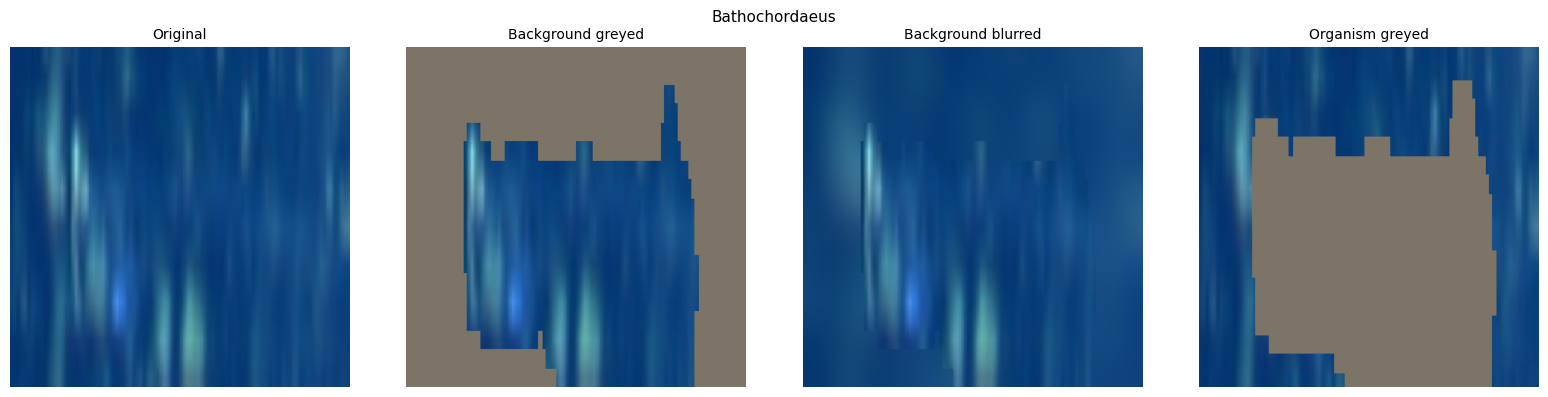

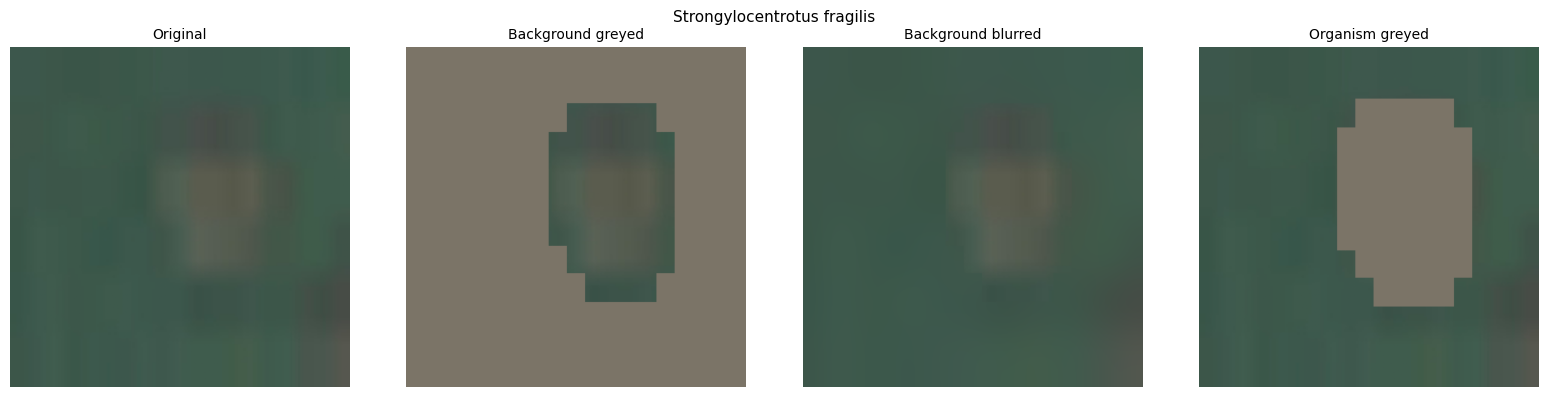

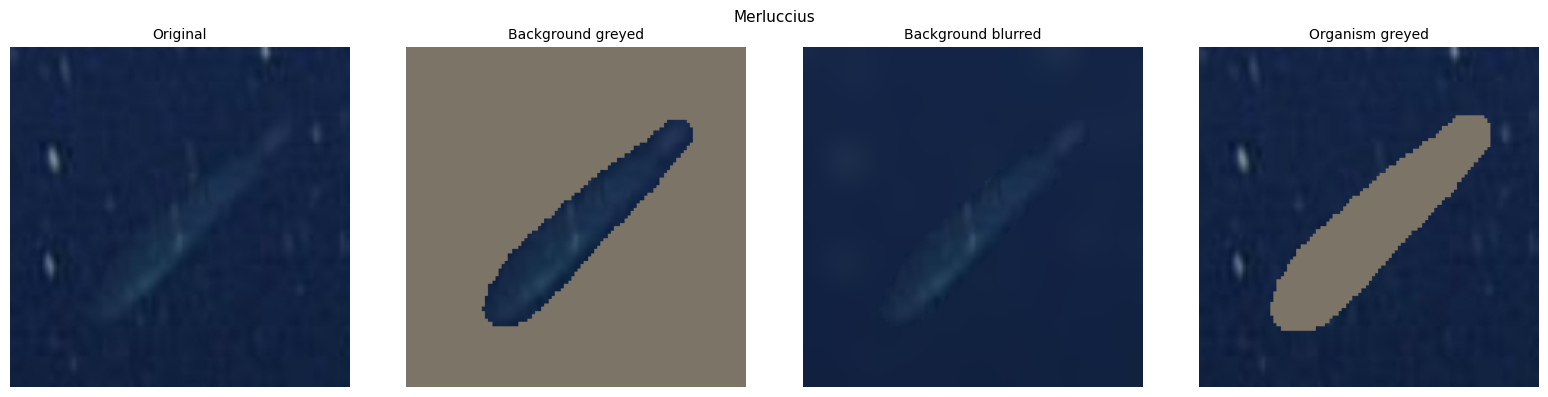

In [21]:
import importlib, extensions
importlib.reload(extensions)

deep_test_mask_loader = data.get_dataloaders(deep_df, split='test', species_list=species_list, coco=coco)
n_new = data.prepare_masks(deep_test_mask_loader)
if n_new:
    data.archive_dir(config.MASK_DIR, config.MASK_ARCHIVE)   # adds the deep masks to the shared masks.tar
mask_loaders = {'shallow': shallow_test_mask_loader, 'deep': deep_test_mask_loader}

extensions.show_interventions(shallow_test_mask_loader, idxs=[0, 20, 25])   # look at the edited crops

## Background Intervention

shallow: 21323 crops x 4 modes x 2 models done
deep: 12926 crops x 4 modes x 2 models done


shallow_acc  deep_acc  degradation  n_species
model   mode                                                             
shallow Original                  0.600     0.440        0.160        139
        Background greyed         0.261     0.204        0.057        139
        Background blurred        0.453     0.341        0.113        139
        Organism greyed           0.058     0.035        0.023        139
control Original                  0.636     0.665       -0.029        139
        Background greyed         0.286     0.322       -0.036        139
        Background blurred        0.493     0.519       -0.027        139
        Organism greyed           0.089     0.086        0.003        139

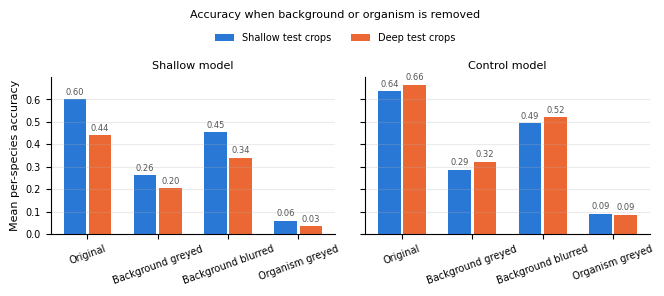

CRS vs accuracy drop (Background greyed): rho = 0.281, p = 0.00117, n = 131 species
CRS vs accuracy drop (Background blurred): rho = 0.159, p = 0.0701, n = 131 species


In [22]:
int_path = os.path.join(config.RESULTS_DIR, 'intervention_predictions.csv')
if os.path.exists(int_path):
    int_preds = pd.read_csv(int_path)
else:
    int_preds = extensions.run_interventions({'shallow': classifier, 'control': control},
                                             mask_loaders, species_list)
    int_preds.to_csv(int_path, index=False)

int_summary = extensions.intervention_summary(int_preds, species=qualifying)
int_summary.to_csv(os.path.join(config.RESULTS_DIR, 'intervention_summary.csv'))
display(int_summary.round(3))
extensions.plot_intervention_summary(int_summary, save_path='results/intervention_accuracy.png')

# Does greying the background hurt the species Grad-CAM said rely on it?
bg_dep, bg_dep_stats = extensions.background_dependence(int_preds, crs_scores, species=qualifying)

In [23]:
cs_shallow = extensions.colour_stats(shallow_test_mask_loader)
cs_deep = extensions.colour_stats(deep_test_mask_loader)
shift = extensions.species_shift(cs_shallow, cs_deep)
per_species_df = per_species_df.drop(columns=shift.columns, errors='ignore').join(shift)
per_species_df.to_csv(os.path.join(config.RESULTS_DIR, 'results.csv'))

spear, grid, fit = extensions.shift_analysis(per_species_df, species=qualifying)
display(spear.round(3))
display(grid.round(3))
print(fit.summary())

Shift analysis over 139 species


,spearman_rho,p_value
predictor,,
bg_colour_shift,0.060,0.480
org_colour_shift,0.180,0.034
crs,-0.199,0.019


mean                      count             
shift_group high bg shift low bg shift high bg shift low bg shift
crs_group                                                        
high CRS            0.155        0.123            34           35
low CRS             0.180        0.179            35           35

                            OLS Regression Results                            
Dep. Variable:            degradation   R-squared:                       0.090
Model:                            OLS   Adj. R-squared:                  0.063
Method:                 Least Squares   F-statistic:                     3.314
Date:                Tue, 27 Oct 2026   Prob (F-statistic):             0.0127
Time:                        06:04:18   Log-Likelihood:                 2.0172
No. Observations:                 139   AIC:                             5.966
Df Residuals:                     134   BIC:                             20.64
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept        0.1597      0.021      7.750   

## Background Swap

Background bank: 1000 donors from 21323 crops
Background bank: 1000 donors from 12926 crops


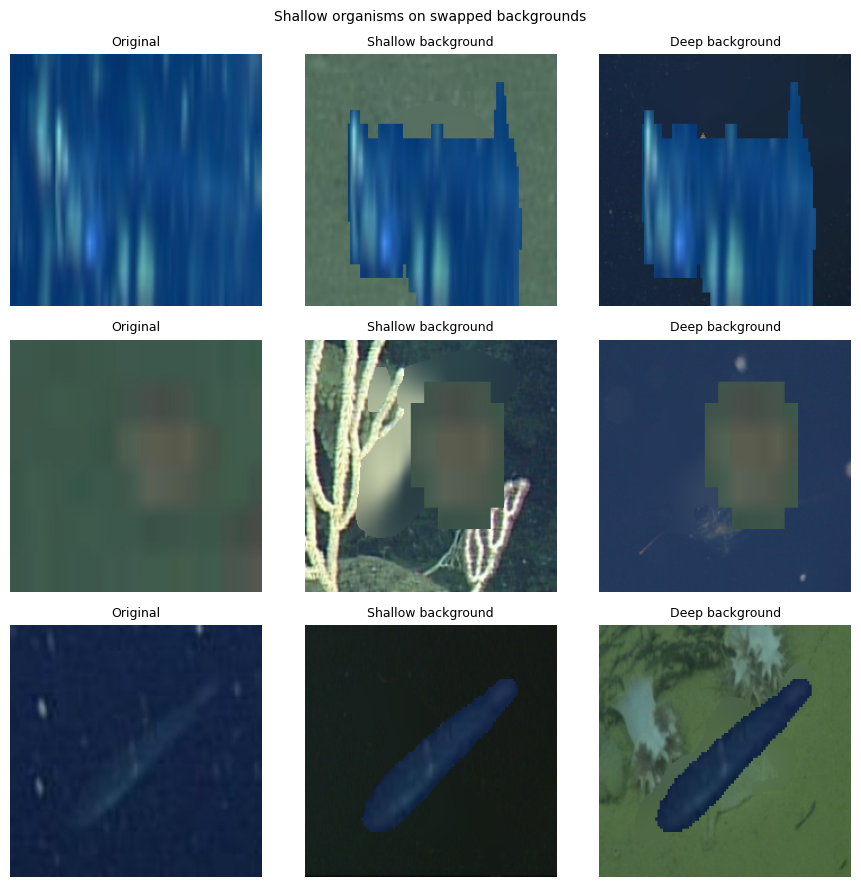

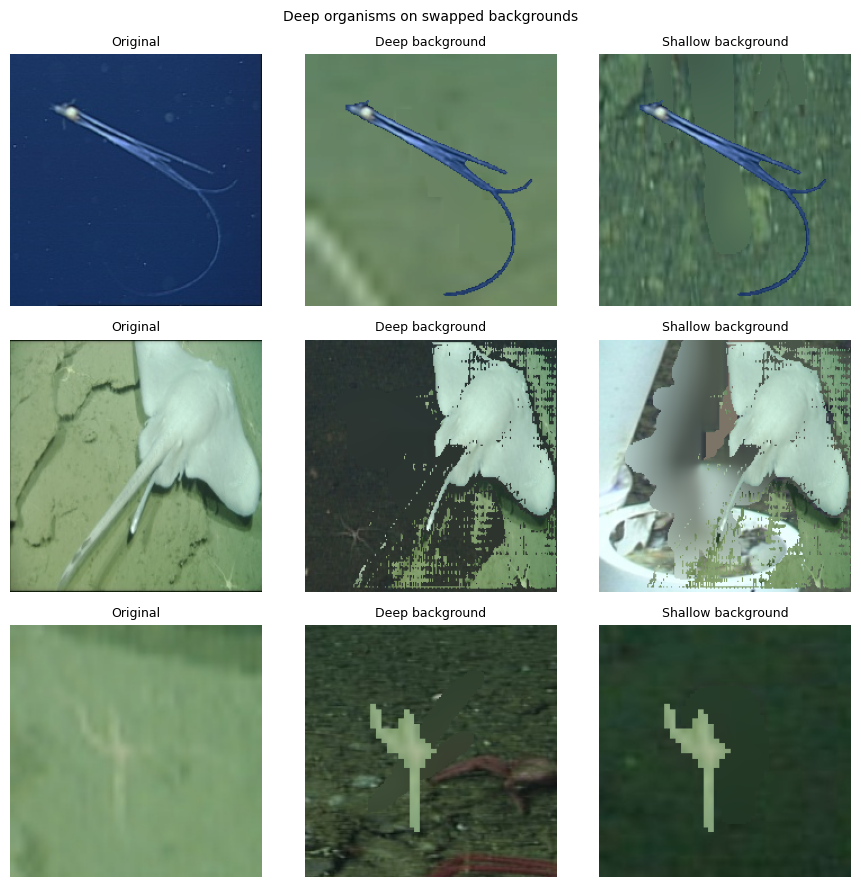

shallow: 21323 crops x 3 modes x 2 models done
deep: 12926 crops x 3 modes x 2 models done


In [24]:
# Background swap: paste each organism onto a same-depth and an other-depth background
importlib.reload(extensions)

swap_path = os.path.join(config.RESULTS_DIR, 'swap_predictions.csv')
if os.path.exists(swap_path):
    print(f"Reusing cached swap predictions from {swap_path}")
    swap_preds = pd.read_csv(swap_path)
else:
    # Building the donor background banks iterates every crop in both loaders, and the composites
    # below are only visual sanity checks. Both are needed just to produce swap_preds, so they run
    # only when the predictions aren't cached yet (delete swap_predictions.csv to force a rebuild).
    banks = {s: extensions.build_background_bank(l) for s, l in mask_loaders.items()}

    # Look at some composites before trusting the numbers
    extensions.show_swaps(mask_loaders, banks, split='shallow', idxs=[0, 20, 25],
                          save_path='results/swap_examples_shallow.png')
    extensions.show_swaps(mask_loaders, banks, split='deep', idxs=[0, 20, 25],
                          save_path='results/swap_examples_deep.png')

    swap_preds = extensions.run_background_swap({'shallow': classifier, 'control': control},
                                                mask_loaders, banks, species_list)
    swap_preds.to_csv(swap_path, index=False)

[shallow] median CRS correct 0.376 vs incorrect 0.501 (pooled p = 5.56e-101); within 101 species, median diff = 0.098 (p = 4.25e-15); empty maps left out: 0 correct, 32 wrong
[deep] median CRS correct 0.434 vs incorrect 0.594 (pooled p = 2.98e-125); within 100 species, median diff = 0.130 (p = 5.05e-15); empty maps left out: 0 correct, 85 wrong


,split,n_correct,n_incorrect,median_crs_correct,median_crs_incorrect,n_empty_correct,n_empty_incorrect,p_pooled,n_species_within,median_within_species_diff,p_within
0,shallow,10741,2778,0.3758,0.5013,0,32,0.0,101,0.0977,0.0
1,deep,6403,3952,0.4338,0.5941,0,85,0.0,100,0.1297,0.0


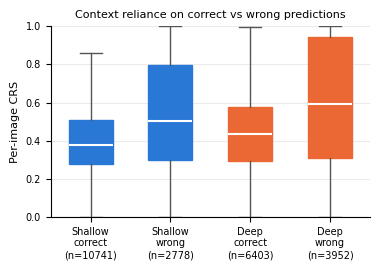

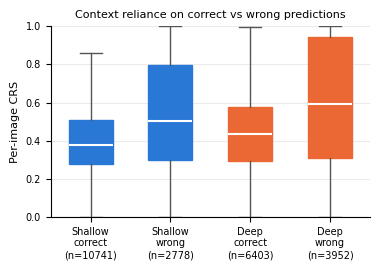

In [25]:
img_crs_path = os.path.join(config.RESULTS_DIR, 'image_crs.csv')
# The shallow half is the table section 5 averaged the species CRS from. A cached deep half is
# reused only if it was scored the current way (has crs_pred); otherwise it is recomputed
cached = pd.read_csv(img_crs_path) if os.path.exists(img_crs_path) else None
if cached is not None and 'crs_pred' in cached.columns:
    image_crs_deep = cached[cached['split'] == 'deep'].drop(columns='split')
else:
    image_crs_deep = attribution.compute_image_crs(classifier, deep_test_mask_loader)
image_crs = {'shallow': image_crs_shallow, 'deep': image_crs_deep}
pd.concat([df.assign(split=s) for s, df in image_crs.items()]).to_csv(img_crs_path, index=False)

# Species CRS on the deep test crops, saved next to the shallow columns (deep_crs, deep_crs_median, ...);
# its bootstrap CIs are added to crs_bootstrap.csv
deep_crs_df = attribution.species_crs_table(image_crs_deep, species_list, prefix='deep_')
deep_ci_cols = ['deep_crs_ci_low', 'deep_crs_ci_high']
deep_boot = deep_crs_df[['deep_crs', *deep_ci_cols, 'deep_n_crs']]
crs_bootstrap = crs_bootstrap.drop(columns=deep_boot.columns, errors='ignore').join(deep_boot)
crs_bootstrap.to_csv(os.path.join(config.RESULTS_DIR, 'crs_bootstrap.csv'))
deep_crs_df = deep_crs_df.drop(columns=deep_ci_cols)
per_species_df = per_species_df.drop(columns=[*deep_ci_cols, *deep_crs_df.columns], errors='ignore').join(deep_crs_df)
per_species_df.to_csv(os.path.join(config.RESULTS_DIR, 'results.csv'))

cw = pd.DataFrame([extensions.crs_correct_vs_incorrect(image_crs[s], species=qualifying, label=s)
                   for s in ['shallow', 'deep']])
cw.to_csv(os.path.join(config.RESULTS_DIR, 'crs_correct_vs_incorrect.csv'), index=False)
display(cw.round(4))
extensions.plot_crs_correct_vs_incorrect(image_crs, species=qualifying,
                                         save_path='results/crs_correct_vs_wrong.png')

In [26]:
# Control model's per-image CRS on the same test crops (for CRS vs depth in the analysis notebook)
ctrl_crs_path = os.path.join(config.RESULTS_DIR, 'image_crs_control.csv')
if os.path.exists(ctrl_crs_path):
    image_crs_control = pd.read_csv(ctrl_crs_path)
else:
    image_crs_control = pd.concat([attribution.compute_image_crs(control, l).assign(split=s)
                                   for s, l in mask_loaders.items()], ignore_index=True)
    image_crs_control.to_csv(ctrl_crs_path, index=False)

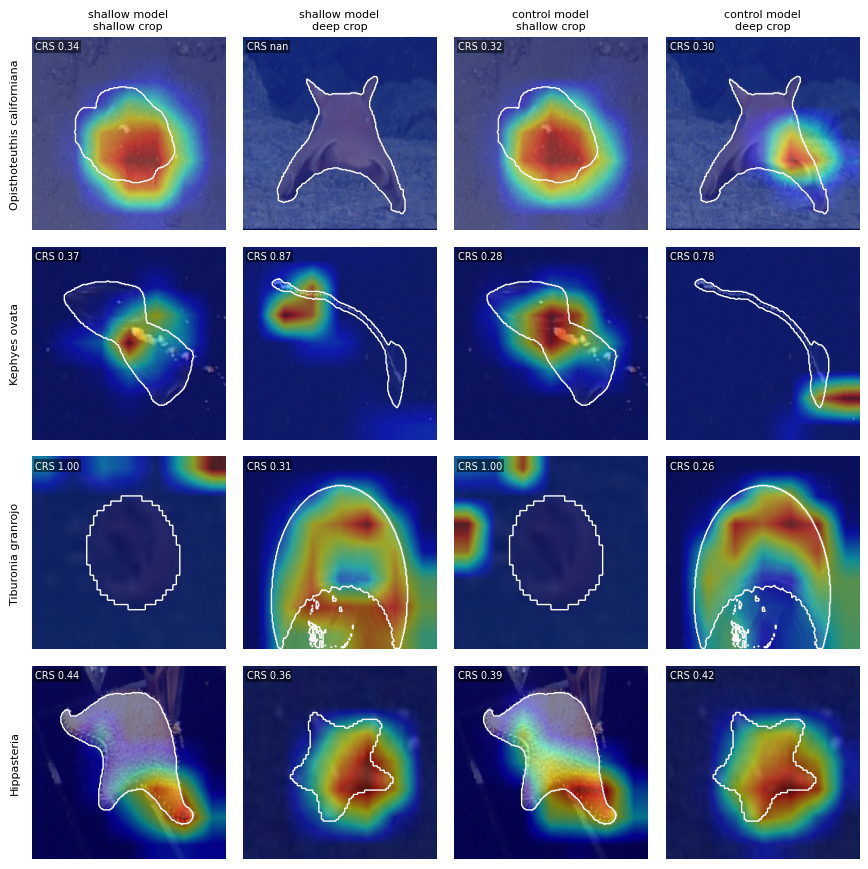

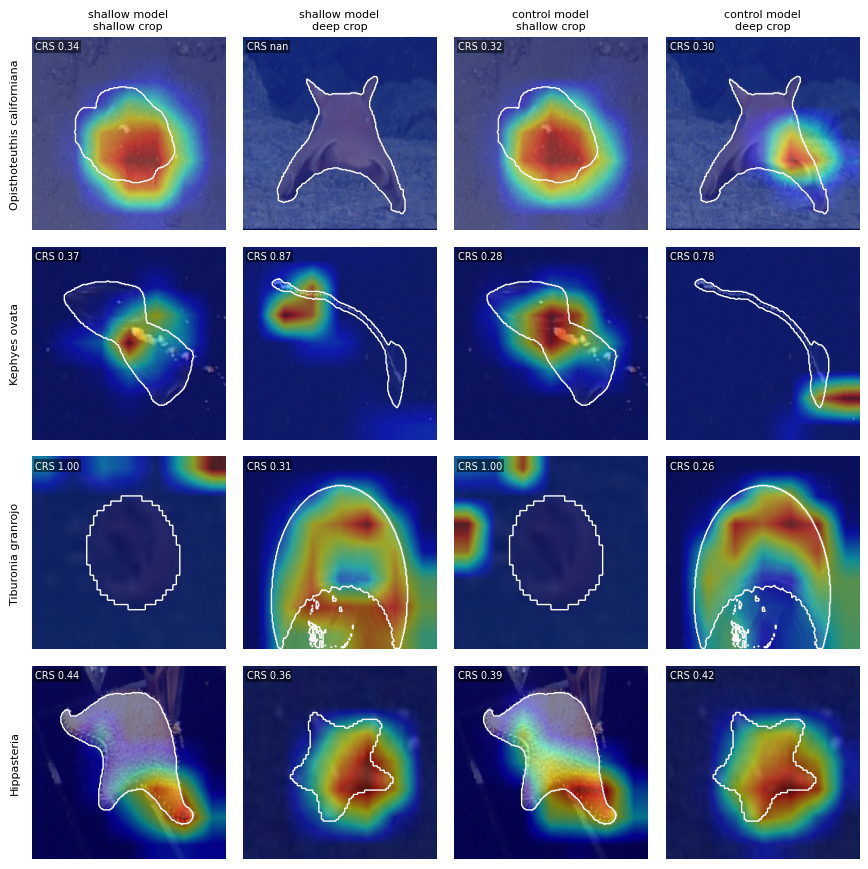

In [27]:
# Does attribution move off the organism in deep crops, and does the control's stay on it?
# Rows: the 2 most- and 2 least-degrading species among those the model learned (shallow acc >= 0.3)
importlib.reload(extensions)
learned = [s for s in qualifying if per_species_df.loc[s, 'shallow_acc'] >= 0.3]
deg = per_species_df.loc[learned, 'degradation'].sort_values()
grid_species = [*deg.index[-2:][::-1], *deg.index[:2]]
extensions.plot_attribution_grid({'shallow': classifier, 'control': control}, mask_loaders,
                                 grid_species, save_path='results/attribution_grid.png')

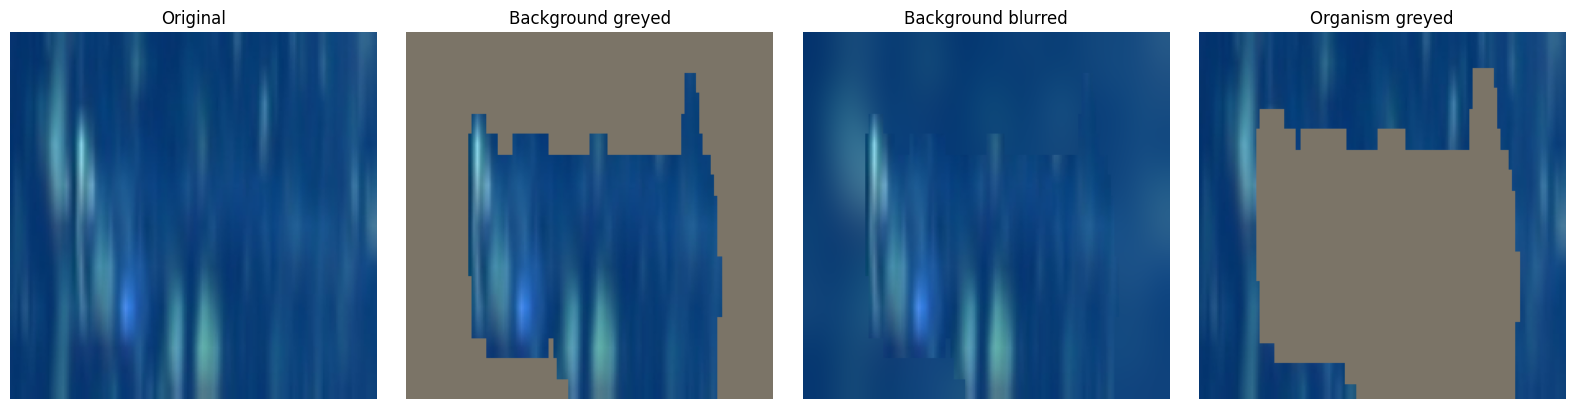

In [28]:
import matplotlib.pyplot as plt
import torch

idx = 0   # which shallow test crop to show; try 20 or 25 if this one isn't clear
img, label, mask = shallow_test_mask_loader.dataset[idx]
mean = torch.tensor(data.IMAGENET_MEAN).view(1, 3, 1, 1)
std = torch.tensor(data.IMAGENET_STD).view(1, 3, 1, 1)

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, mode in zip(axes, extensions.MODES):
    x = extensions.apply_intervention(img[None], mask[None], mode)
    ax.imshow((x * std + mean).clamp(0, 1)[0].permute(1, 2, 0).numpy())
    ax.set_title(extensions.MODE_LABELS[mode], fontsize=12)
    ax.axis('off')
plt.tight_layout()
fig.savefig('results/intervention_examples.png', dpi=150, bbox_inches='tight')
plt.show()

## CRS with same-species masks (sensitivity check)
The main CRS treats only the target annotation as organism, so another
individual of the same species in the crop counts as context. 

In [29]:
# Same test crops as section 5, with every same-species annotation in the crop masked as organism
species_mask_loaders = {s: data.get_dataloaders(d, split='test', species_list=species_list, coco=coco,
                                                mask_mode='same_species')
                        for s, d in [('shallow', shallow_df), ('deep', deep_df)]}
n_new = sum(data.prepare_masks(l) for l in species_mask_loaders.values())
if n_new:
    data.archive_dir(config.MASK_DIR, config.MASK_ARCHIVE)   # adds the same-species masks to the shared masks.tar

# Per-image CRS on both splits. extra_organisms marks crops where another individual of the
# species adds to the mask (the only crops whose CRS can differ from image_crs.csv)
img_crs_sp_path = os.path.join(config.RESULTS_DIR, 'image_crs_same_species.csv')
# A cache from before predicted-class CRS (no crs_pred column) is recomputed
if os.path.exists(img_crs_sp_path) and 'crs_pred' in pd.read_csv(img_crs_sp_path, nrows=0).columns:
    all_ic_sp = pd.read_csv(img_crs_sp_path)
    image_crs_sp = {s: all_ic_sp[all_ic_sp['split'] == s].drop(columns='split') for s in ['shallow', 'deep']}
else:
    image_crs_sp = {}
    for s, loader in species_mask_loaders.items():
        target_ds, species_ds = mask_loaders[s].dataset, loader.dataset
        assert target_ds.ann_ids == species_ds.ann_ids   # same crops in the same order
        ic = attribution.compute_image_crs(classifier, loader)
        ic['extra_organisms'] = [bool((species_ds.get_mask(i) > target_ds.get_mask(i)).any())
                                 for i in range(len(species_ds))]
        image_crs_sp[s] = ic
    pd.concat([df.assign(split=s) for s, df in image_crs_sp.items()]).to_csv(img_crs_sp_path, index=False)

for s, ic in image_crs_sp.items():
    print(f"{s}: {ic['extra_organisms'].mean():.1%} of {len(ic)} test crops contain another "
          f"annotated individual of the same species")

# Per-species CRS for each split (shallow_* and deep_* columns, as in results.csv) and shallow baselines
crs_species_df = pd.concat([attribution.species_crs_table(ic, species_list, prefix=f'{s}_')
                            for s, ic in image_crs_sp.items()], axis=1)
for kind in ('uniform', 'gaussian'):
    crs_species_df[f'{kind}_crs'] = pd.Series(attribution.compute_species_baseline_crs(
        species_mask_loaders['shallow'], species_list, kind))
crs_species_df.to_csv(os.path.join(config.RESULTS_DIR, 'crs_same_species.csv'))

test: 21323 crops, 314 classes
test: 12926 crops, 314 classes
Masks: 0 newly saved, 21323 already cached in /content/masks/
Masks: 0 newly saved, 12926 already cached in /content/masks/
shallow: 15.4% of 21323 test crops contain another annotated individual of the same species
deep: 12.0% of 12926 test crops contain another annotated individual of the same species
uniform baseline CRS: scored 21323 / 21323 images
gaussian baseline CRS: scored 21323 / 21323 images


## Robustness check: size-matched control
Trained on all depths like the control, but on a random subsample of the all-depth train and val crops
with the same total number of crops as the shallow model's train and val sets (class counts are not matched).
Results are saved to separate files; the main control and `results.csv` are not changed.


In [30]:
# Build the size-matched train / val sets
import time

# Same image-level split as data.get_dataloaders (it hashes config.RANDOM_SEED with the image id)
split_seed = getattr(config, "RANDOM_SEED", 42)
assign = {i: data._split_of(i, split_seed, config.VAL_SPLIT, config.TEST_SPLIT)
          for i in all_df["image_id"].unique()}
row_split = all_df["image_id"].map(assign)

n_train, n_val = len(train_loader.dataset), len(val_loader.dataset)
rng = np.random.default_rng(config.RANDOM_SEED)

def subsample(rows, n):
    if n > len(rows):
        raise ValueError(f"need {n} rows but only {len(rows)} available")
    return rows.iloc[np.sort(rng.choice(len(rows), size=n, replace=False))]

matched_train_df = subsample(all_df[row_split == "train"], n_train)
matched_val_df   = subsample(all_df[row_split == "val"], n_val)

matched_train_loader = data.get_dataloaders(matched_train_df, split="train", species_list=species_list)
matched_val_loader   = data.get_dataloaders(matched_val_df, split="val", species_list=species_list)
assert len(matched_train_loader.dataset) == n_train and len(matched_val_loader.dataset) == n_val

shallow_share = lambda d: (d["depth_m"] <= config.DEPTH_SHALLOW_MAX).mean()
print(f"Train crops: shallow model {n_train}, matched control {len(matched_train_df)}"
      + ("" if SKIP_CONTROL else f", full control {len(all_loader.dataset)}"))
print(f"Val crops:   shallow model {n_val}, matched control {len(matched_val_df)}"
      + ("" if SKIP_CONTROL else f", full control {len(all_val_loader.dataset)}"))
print(f"Matched control: {shallow_share(matched_train_df):.1%} of train crops are shallow, "
      f"{matched_train_df['species'].nunique()} of {len(species_list)} species have training crops")


train: 73711 crops, 314 classes
val: 10811 crops, 314 classes
Train crops: shallow model 73711, matched control 73711, full control 121132
Val crops:   shallow model 10811, matched control 10811, full control 17699
Matched control: 61.0% of train crops are shallow, 314 of 314 species have training crops


In [31]:
# Train the size-matched control (or load its checkpoint)
matched_ckpt_path = config.MODEL_SAVE_PATH + "control_matched_resnet50.pt"

model.set_seed(config.RANDOM_SEED)
control_matched = model.build_classifier(num_classes=len(species_list), pretrained=config.PRETRAINED)

if os.path.exists(matched_ckpt_path):
    print(f"Found existing checkpoint at {matched_ckpt_path} - loading instead of retraining")
    control_matched = model.load_checkpoint(control_matched, matched_ckpt_path)
    matched_trained = False
else:
    t0 = time.time()
    control_matched, matched_history = model.train(control_matched, matched_train_loader, matched_val_loader,
                                                   epochs=config.EPOCHS, lr=config.LEARNING_RATE,
                                                   resume_path=matched_ckpt_path + ".resume")
    model.save_checkpoint(control_matched, matched_ckpt_path)
    np.save(os.path.join(config.MODEL_SAVE_PATH, "control_matched_history.npy"),
            np.array(matched_history["val_acc"]))
    print(f"Matched control training took {(time.time() - t0) / 60:.1f} min, saved to {matched_ckpt_path}")
    matched_trained = True


Random seed set to 42
Epoch 1/12 | train_loss=1.5181 train_acc=0.6517 | val_loss=0.8999 val_acc=0.7565
Epoch 2/12 | train_loss=0.6560 train_acc=0.8093 | val_loss=0.7416 val_acc=0.7910
Epoch 3/12 | train_loss=0.4652 train_acc=0.8573 | val_loss=0.7144 val_acc=0.7972
Epoch 4/12 | train_loss=0.3551 train_acc=0.8867 | val_loss=0.7271 val_acc=0.8029
Epoch 5/12 | train_loss=0.2790 train_acc=0.9087 | val_loss=0.7467 val_acc=0.8034
Epoch 6/12 | train_loss=0.2144 train_acc=0.9295 | val_loss=0.7960 val_acc=0.7987
Epoch 7/12 | train_loss=0.1740 train_acc=0.9427 | val_loss=0.8170 val_acc=0.8052
Epoch 8/12 | train_loss=0.1453 train_acc=0.9523 | val_loss=0.8032 val_acc=0.8110
Epoch 9/12 | train_loss=0.1206 train_acc=0.9599 | val_loss=0.8385 val_acc=0.8052
Epoch 10/12 | train_loss=0.1008 train_acc=0.9673 | val_loss=0.9049 val_acc=0.8027
Epoch 11/12 | train_loss=0.0927 train_acc=0.9701 | val_loss=0.8764 val_acc=0.8053
Early stopping: no val improvement for 3 epochs
Matched control training took 72.4 mi

In [32]:
# Evaluate on the same shallow and deep test crops as the shallow model, and save the values separately
from scipy.stats import spearmanr

matched_pred_path = os.path.join(config.RESULTS_DIR, "control_matched_predictions.csv")
if os.path.exists(matched_pred_path) and not matched_trained:
    print(f"Reusing cached matched-control predictions from {matched_pred_path}")
    mp = pd.read_csv(matched_pred_path)
else:
    m = evaluation.evaluate_control_model(control_matched, shallow_test_loader, deep_test_loader, species_list)
    mp = pd.concat([m["shallow_preds"].assign(split="shallow"), m["deep_preds"].assign(split="deep")],
                   ignore_index=True)
    mp.to_csv(matched_pred_path, index=False)

# Same test crops, in the same order, as the shallow model (and so as the full control)
for s, preds in [("shallow", shallow_preds), ("deep", deep_preds)]:
    assert mp.loc[mp["split"] == s, "ann_id"].tolist() == preds["ann_id"].tolist(), f"{s} test crops differ"
print("Matched control was scored on exactly the same shallow and deep test crops as the shallow model")

m_shallow_acc = evaluation.accuracy_from_predictions(mp[mp["split"] == "shallow"], species_list)
m_deep_acc    = evaluation.accuracy_from_predictions(mp[mp["split"] == "deep"], species_list)
matched_species = pd.DataFrame({"matched_shallow_acc": pd.Series(m_shallow_acc),
                                "matched_deep_acc": pd.Series(m_deep_acc)})
matched_species["matched_degradation"] = matched_species["matched_shallow_acc"] - matched_species["matched_deep_acc"]
matched_species.index.name = "species"
matched_species.to_csv(os.path.join(config.RESULTS_DIR, "control_matched_per_species.csv"))

# Summary over the qualifying species: all three models, and the main test with matched-control-adjusted degradation
q = per_species_df.loc[qualifying].join(matched_species)
summary_rows = []
for name, sh, dp in [("shallow", "shallow_acc", "deep_acc"),
                     ("control", "control_shallow_acc", "control_deep_acc"),
                     ("matched control", "matched_shallow_acc", "matched_deep_acc")]:
    summary_rows.append({"model": name, "shallow_acc": q[sh].mean(), "deep_acc": q[dp].mean(),
                         "degradation": (q[sh] - q[dp]).mean(), "n_species": len(q)})

ic_sh = image_crs["shallow"]
crs_correct = ic_sh[ic_sh["correct"]].dropna(subset=["crs"]).groupby("species")["crs"].mean()
for label, deg in [("degradation", q["degradation"]),
                   ("degradation - control degradation", q["degradation"] - q["control_degradation"]),
                   ("degradation - matched control degradation", q["degradation"] - q["matched_degradation"])]:
    d = pd.concat([crs_correct, deg], axis=1, keys=["crs", "deg"]).dropna()
    rho, p = spearmanr(d["crs"], d["deg"])
    summary_rows.append({"model": f"CRS (correct only) vs {label}", "rho": rho, "p": p, "n_species": len(d)})

matched_summary = pd.DataFrame(summary_rows)
matched_summary.to_csv(os.path.join(config.RESULTS_DIR, "control_matched_summary.csv"), index=False)
display(matched_summary.round(3))


Matched control was scored on exactly the same shallow and deep test crops as the shallow model


,model,shallow_acc,deep_acc,degradation,n_species,rho,p
0,shallow,0.600,0.440,0.160,139,NaN,NaN
1,control,0.636,0.665,-0.029,139,NaN,NaN
2,matched control,0.585,0.634,-0.049,139,NaN,NaN
3,CRS (correct only) vs degradation,NaN,NaN,NaN,131,-0.060,0.496
4,CRS (correct only) vs degradation - control de...,NaN,NaN,NaN,131,-0.091,0.302
5,CRS (correct only) vs degradation - matched co...,NaN,NaN,NaN,131,-0.100,0.256


# Limitation of Grad-CAM's spatial resolution

Species: Bathochordaeus
Total grid cells: 49
Mixed cells: 23
Percentage mixed: 46.9%


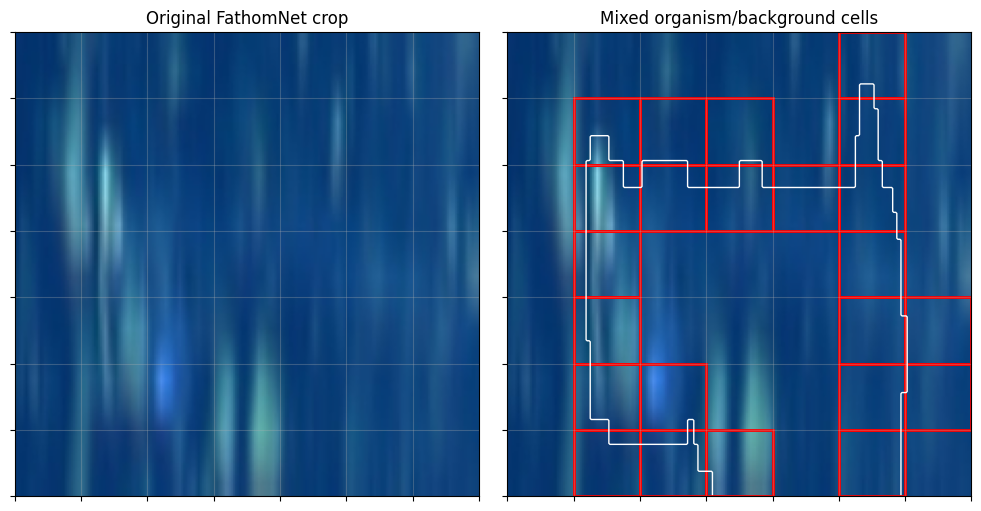

In [ ]:
import torch.nn.functional as F

# Use an existing real FathomNet test crop and mask
idx = 0  # Try 20, 25, or 30 for other examples
img, label, mask_tensor = shallow_test_mask_loader.dataset[idx]

mask = (mask_tensor.cpu().numpy() > 0).astype(np.float32)

# Confirm the mask is 224 x 224
assert mask.shape == (224, 224)

# Calculate organism coverage in each 32 x 32 grid region
coverage = F.avg_pool2d(
    torch.tensor(mask)[None, None],
    kernel_size=32,
    stride=32
)[0, 0].numpy()

# Mixed cells contain both organism and background
mixed = (coverage > 0) & (coverage < 1)

print("Species:", species_list[label])
print("Total grid cells:", mixed.size)
print("Mixed cells:", mixed.sum())
print("Percentage mixed:", f"{mixed.mean() * 100:.1f}%")

# Convert the normalized image back to RGB
mean = torch.tensor(data.IMAGENET_MEAN).view(3, 1, 1)
std = torch.tensor(data.IMAGENET_STD).view(3, 1, 1)
rgb = (img.cpu() * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(rgb)
axes[0].set_title("Original FathomNet crop")

axes[1].imshow(rgb)

# Draw the 7 x 7 grid and highlight mixed cells
for r in range(7):
    for c in range(7):
        if mixed[r, c]:
            axes[1].add_patch(
                plt.Rectangle(
                    (c * 32 - 0.5, r * 32 - 0.5),
                    32, 32,
                    fill=False,
                    edgecolor="red",
                    linewidth=2
                )
            )

axes[1].contour(mask, levels=[0.5], colors="white", linewidths=1)
axes[1].set_title("Mixed organism/background cells")

for ax in axes:
    ax.set_xticks(np.arange(-0.5, 224, 32))
    ax.set_yticks(np.arange(-0.5, 224, 32))
    ax.grid(alpha=0.3)
    ax.set_xticklabels([])
    ax.set_yticklabels([])

plt.tight_layout()
plt.savefig("fathomnet_mixed_gradcam_cells.png", dpi=300, bbox_inches="tight")
plt.show()
